# NetGuard: data audit, EDA and held-out evaluation

Executed against the bundled dataset and model artifacts. This notebook analyses existing results; it does not retrain or tune on test data. Run python -m src.train from project root to reproduce training. Attribution: S., B. & Nagapadma, R. (2023), RT-IoT2022, UCI, DOI 10.24432/C5P338, CC BY 4.0.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.download import main as download
from src.core import load_bundle, predict, explain
download()
raw = pd.read_csv(ROOT / 'data/raw/RT_IOT2022')
audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
metrics = json.loads((ROOT / 'reports/metrics.json').read_text())
print('Raw shape:', raw.shape)
print('Missing cells:', raw.isna().sum().sum())


Ready: /workspace/scratch/8424f2a17b04/netguard/data/raw/RT_IOT2022
Raw shape: (123117, 85)
Missing cells: 0


## 1. Understand imbalance before modeling

The original flood class dominates raw row volume. Use the labels in the actual downloaded file.

Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28


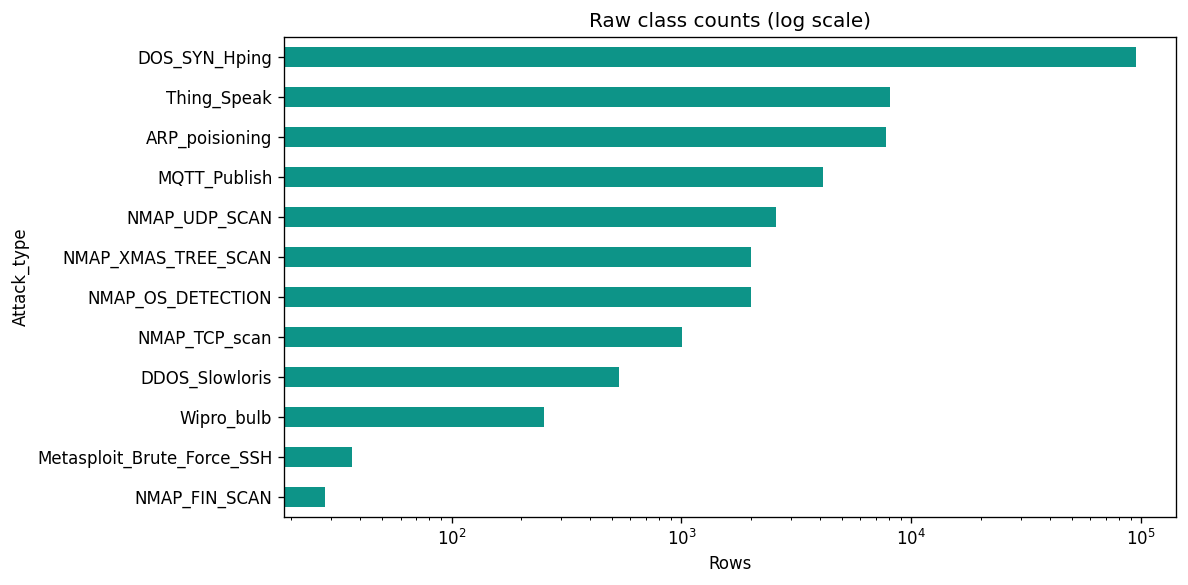

In [2]:
counts = raw.Attack_type.value_counts()
print(counts.to_string())
fig, ax = plt.subplots(figsize=(10,5))
counts.sort_values().plot.barh(ax=ax, color='#0d9488', logx=True)
ax.set(title='Raw class counts (log scale)', xlabel='Rows')
fig.tight_layout()


## 2. Leakage audit

Ports, index and target are excluded. Hash only retained features; remove conflicting collapsed-family groups and exact duplicates. This changes prevalence. Near duplicates and shared capture context remain possible.

In [3]:
print(pd.Series({k:audit[k] for k in ['raw_rows','conflict_rows_removed','duplicate_rows_removed','unique_rows_used','model_features','overlapping_feature_hashes']}).to_string())
manifest = pd.read_csv(ROOT / 'reports/split_manifest.csv', dtype={'feature_hash':str})
assert not manifest.feature_hash.duplicated().any()
print('Split sizes:')
print(manifest.split.value_counts().to_string())
print('Family counts after deduplication:')
print(pd.DataFrame({k:v['families'] for k,v in audit['splits'].items()}).fillna(0).astype(int).to_string())


raw_rows                      123117
conflict_rows_removed            611
duplicate_rows_removed        104244
unique_rows_used               18262
model_features                    81
overlapping_feature_hashes         0
Split sizes:
split
train         10957
test           3653
validation     3652
Family counts after deduplication:
                            train  validation  test
Benign                       7171        2390  2391
ARP_poisioning               3174        1058  1058
DDOS_Slowloris                319         106   107
NMAP_UDP_SCAN                 115          38    39
NMAP_XMAS_TREE_SCAN            48          16    16
NMAP_OS_DETECTION              45          15    15
DOS_SYN_Hping                  34          12    11
NMAP_TCP_scan                  27           9     8
Metasploit_Brute_Force_SSH     21           7     7
NMAP_FIN_SCAN                   3           1     1


## 3. Compare models without tuning on test

Training fits preprocessing and model weights. Validation selects model and threshold. Do not revise choices using this test table and continue calling it an untouched final test.

In [4]:
columns=['average_precision','precision','recall','f2','false_positive_rate','threshold']
print('VALIDATION')
print(pd.DataFrame(metrics['validation']).T[columns].to_string())
print('TEST')
print(pd.DataFrame(metrics['test']).T[columns].round(5).to_string())
print('Selected:', metrics['selected_model'])


VALIDATION
                    average_precision precision    recall        f2 false_positive_rate threshold
Majority baseline            0.345564       0.0       0.0       0.0                 0.0       1.0
Logistic regression          0.981329  0.981083   0.90412  0.918532            0.009205   0.88913
Random forest                0.999229  0.981975  0.992868   0.99067            0.009623  0.531748
TEST
                     average_precision  precision   recall       f2  false_positive_rate  threshold
Majority baseline              0.34547    0.00000  0.00000  0.00000              0.00000    1.00000
Logistic regression            0.97981    0.98000  0.93185  0.94110              0.01004    0.88913
Random forest                  0.99901    0.97665  0.99445  0.99084              0.01255    0.53175
Selected: Random forest


## 4. Inspect mistakes

The validation FPR target is not a guarantee on test or future traffic.

Errors: 37
  ground_truth  attack_score  alert family_prediction
        Benign      0.784523   True    ARP_poisioning
        Benign      0.552588   True            Benign
        Benign      0.541371   True    ARP_poisioning
        Benign      0.841781   True    ARP_poisioning
ARP_poisioning      0.330733  False            Benign
        Benign      0.803862   True    ARP_poisioning
ARP_poisioning      0.505109  False    ARP_poisioning
 NMAP_UDP_SCAN      0.216275  False            Benign
 NMAP_UDP_SCAN      0.216275  False            Benign
        Benign      0.993298   True    ARP_poisioning
        Benign      0.617101   True            Benign
ARP_poisioning      0.249489  False            Benign
        Benign      0.852857   True    ARP_poisioning
        Benign      0.906003   True    ARP_poisioning
        Benign      0.771705   True    ARP_poisioning


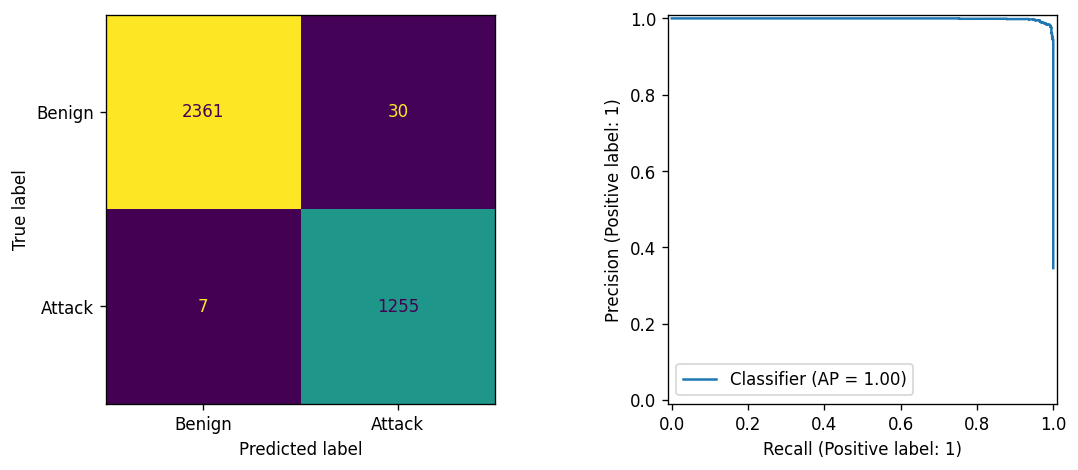

In [5]:
test = pd.read_csv(ROOT / 'reports/test_predictions.csv')
wrong = (test.ground_truth != 'Benign') != test.alert
print('Errors:', int(wrong.sum()))
print(test.loc[wrong, ['ground_truth','attack_score','alert','family_prediction']].head(15).to_string(index=False))
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
y = test.ground_truth.ne('Benign')
fig, axes = plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(y,test.alert,display_labels=['Benign','Attack'],ax=axes[0],colorbar=False)
PrecisionRecallDisplay.from_predictions(y,test.attack_score,ax=axes[1])
fig.tight_layout()


## 5. Rare classes and family identification

Binary alerting and correct family identification are separate tasks. The family model fails the only FIN-scan test record, though the binary detector flags it.

In [6]:
print(pd.DataFrame(metrics['per_family_detection']).T.to_string())
family = {k:v for k,v in metrics['family_classification'].items() if isinstance(v,dict)}
print('Family classification:')
print(pd.DataFrame(family).T.round(4).to_string())


                                 n  alert_rate
ARP_poisioning              1058.0    0.995274
Benign                      2391.0    0.012547
DDOS_Slowloris               107.0    1.000000
DOS_SYN_Hping                 11.0    1.000000
Metasploit_Brute_Force_SSH     7.0    1.000000
NMAP_FIN_SCAN                  1.0    1.000000
NMAP_OS_DETECTION             15.0    1.000000
NMAP_TCP_scan                  8.0    1.000000
NMAP_UDP_SCAN                 39.0    0.948718
NMAP_XMAS_TREE_SCAN           16.0    1.000000
Family classification:
                            precision  recall  f1-score  support
ARP_poisioning                 0.9741  0.9934    0.9836   1058.0
Benign                         0.9966  0.9891    0.9929   2391.0
DDOS_Slowloris                 0.9533  0.9533    0.9533    107.0
DOS_SYN_Hping                  1.0000  1.0000    1.0000     11.0
Metasploit_Brute_Force_SSH     1.0000  0.8571    0.9231      7.0
NMAP_FIN_SCAN                  0.0000  0.0000    0.0000      1.0
NMAP_

## 6. Global feature importance

Measured on validation using average precision and 3 repeats. Correlated features can substitute for one another. This is diagnostic, not causal.

              feature  mean_ap_drop  std_ap_drop
         flow_iat.min      0.008921     0.000478
          fwd_iat.min      0.000657     0.000045
  fwd_header_size_max      0.000446     0.000027
    fwd_data_pkts_tot      0.000173     0.000011
    fwd_subflow_bytes      0.000168     0.000042
 fwd_pkts_payload.max      0.000122     0.000151
flow_pkts_payload.tot      0.000114     0.000041
 fwd_pkts_payload.std      0.000106     0.000005
 fwd_init_window_size      0.000081     0.000010
          fwd_iat.std      0.000069     0.000025
          bwd_iat.std      0.000067     0.000003
  bwd_header_size_max      0.000066     0.000008


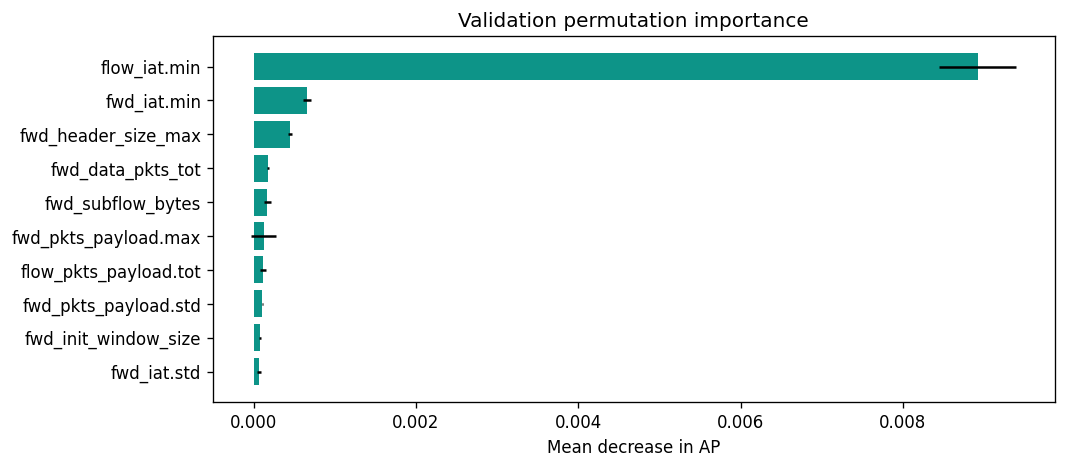

In [7]:
importance = pd.read_csv(ROOT / 'reports/permutation_importance.csv')
print(importance.head(12).round(6).to_string(index=False))
fig, ax = plt.subplots(figsize=(9,4))
top = importance.head(10).iloc[::-1]
ax.barh(top.feature,top.mean_ap_drop,xerr=top.std_ap_drop,color='#0d9488')
ax.set(title='Validation permutation importance',xlabel='Mean decrease in AP')
fig.tight_layout()


## 7. Use the same inference path as the dashboard

Demo examples are from test, sampled up to 25 per family. Their intentionally mixed prevalence is not representative of a deployed network. Labels are kept separate.

In [8]:
bundle = load_bundle()
sample = pd.read_csv(ROOT / 'data/samples/demo_flows.csv')
predictions = pd.DataFrame(predict(sample,bundle))
print(predictions[['flow_id','attack_score','decision','candidate_family']].head(10).to_string(index=False))
idx = int(predictions.attack_score.idxmax())
explanation = explain(sample,idx,bundle)
print('Sensitivity for flow',idx+1)
print(pd.DataFrame(explanation['features']).head(8).to_string(index=False))
print(explanation['caveat'])


 flow_id  attack_score decision    candidate_family
       1      1.000000   Review NMAP_XMAS_TREE_SCAN
       2      1.000000   Review   NMAP_OS_DETECTION
       3      0.993706   Review       DOS_SYN_Hping
       4      1.000000   Review      ARP_poisioning
       5      1.000000   Review   NMAP_OS_DETECTION
       6      0.000000 No alert                   —
       7      0.993487   Review      DDOS_Slowloris
       8      0.000000 No alert                   —
       9      0.993455   Review      ARP_poisioning
      10      0.999979   Review       NMAP_UDP_SCAN
Sensitivity for flow 1
              feature  observed  benign_reference  score_change
          fwd_iat.min  0.000000        241.041183      0.071663
         flow_iat.min  2.861023        192.880630      0.047502
  bwd_header_size_max 20.000000         40.000000      0.034128
flow_pkts_payload.tot  0.000000        176.000000      0.024260
          bwd_iat.min  0.000000        220.060349      0.023667
    fwd_data_pkts_tot

## 8. Next research question

Can a frozen model and verified matching extractor preserve useful recall with manageable alert volume on unseen devices and later captures? Collect independent data, group by device/session/time, and evaluate at realistic prevalence. This experiment does not establish zero-day or enterprise readiness.